In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

artifacts = joblib.load("../models/preprocessing_artifacts.pkl")

X_train = artifacts["X_train"]
X_test = artifacts["X_test"]
y_train = artifacts["y_train"]
y_test = artifacts["y_test"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (88416, 92)
Testing data: (22105, 92)
Training labels: (88416,)
Testing labels: (22105,)


In [2]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [3]:
y_pred = logistic_model.predict(X_test)

print("Predictions completed!")
print("First 10 predictions:", y_pred[:10])

Predictions completed!
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 79.60642388599865 %

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.99      0.89     17642
           1       0.38      0.02      0.03      4463

    accuracy                           0.80     22105
   macro avg       0.59      0.50      0.46     22105
weighted avg       0.72      0.80      0.71     22105


Confusion Matrix:
[[17525   117]
 [ 4391    72]]


In [5]:
balanced_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

print("Balanced Logistic Regression trained!")

Balanced Logistic Regression trained!


In [6]:
print("Accuracy:", accuracy_score(y_test, balanced_pred))

print("\nClassification Report:")
print(classification_report(y_test, balanced_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, balanced_pred))

Accuracy: 0.652838724270527

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.67      0.76     17642
           1       0.31      0.58      0.40      4463

    accuracy                           0.65     22105
   macro avg       0.59      0.62      0.58     22105
weighted avg       0.75      0.65      0.68     22105


Confusion Matrix:
[[11860  5782]
 [ 1892  2571]]


In [7]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [8]:
rf_pred = random_forest_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 61.99954761366207 %

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.58      0.71     17642
           1       0.32      0.77      0.45      4463

    accuracy                           0.62     22105
   macro avg       0.61      0.67      0.58     22105
weighted avg       0.79      0.62      0.66     22105


Confusion Matrix:
[[10288  7354]
 [ 1046  3417]]


In [9]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=15,
    min_samples_split=20,
    class_weight='balanced',
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [10]:
dt_pred = decision_tree_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Decision Tree Accuracy: 59.710472743723145 %

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.55      0.69     17642
           1       0.30      0.77      0.44      4463

    accuracy                           0.60     22105
   macro avg       0.60      0.66      0.56     22105
weighted avg       0.78      0.60      0.64     22105


Confusion Matrix:
[[9767 7875]
 [1031 3432]]


In [11]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

gradient_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [12]:
gb_pred = gradient_model.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, gb_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, gb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))

Gradient Boosting Accuracy: 57.56163763854332 %

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.51      0.66     17642
           1       0.30      0.84      0.44      4463

    accuracy                           0.58     22105
   macro avg       0.61      0.67      0.55     22105
weighted avg       0.80      0.58      0.61     22105


Confusion Matrix:
[[8994 8648]
 [ 733 3730]]


In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": y_pred,
    "Balanced Logistic Regression": balanced_pred,
    "Random Forest": rf_pred,
    "Decision Tree": dt_pred,
    "Gradient Boosting": gb_pred
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.6200,0.3172,0.7656,0.4486
4,Gradient Boosting,0.5756,0.3013,0.8358,0.4430
3,Decision Tree,0.5971,0.3035,0.7690,0.4353
1,Balanced Logistic Regression,0.6528,0.3078,0.5761,0.4012
0,Logistic Regression,0.7961,0.3810,0.0161,0.0310


In [14]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [15]:
param_dist = {
    'n_estimators': randint(150, 400),
    'max_depth': [10, 15, 20, None],
    'min_samples_split': randint(5, 20),
    'min_samples_leaf': randint(2, 10),
    'max_features': ['sqrt', 'log2', 0.5],
    'class_weight': ['balanced', 'balanced_subsample']
}

print("Random Forest parameter search space created!")

Random Forest parameter search space created!


In [17]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_dist,
    n_iter=5,
    scoring='f1',
    cv=2,
    verbose=1,
    random_state=42,
    n_jobs=1
)

rf_search.fit(X_train, y_train)

print("Best parameters:")
print(rf_search.best_params_)

print("Best CV F1-score:")
print(rf_search.best_score_)

Fitting 2 folds for each of 5 candidates, totalling 10 fits
Best parameters:
{'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'min_samples_split': 15, 'n_estimators': 221}
Best CV F1-score:
0.44915453008236517


In [18]:
best_rf_model = rf_search.best_estimator_

tuned_rf_pred = best_rf_model.predict(X_test)

print("Tuned Random Forest Accuracy:",
      accuracy_score(y_test, tuned_rf_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, tuned_rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_rf_pred))

Tuned Random Forest Accuracy: 62.28907486993893 %

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.59      0.71     17642
           1       0.32      0.77      0.45      4463

    accuracy                           0.62     22105
   macro avg       0.61      0.68      0.58     22105
weighted avg       0.79      0.62      0.66     22105


Confusion Matrix:
[[10338  7304]
 [ 1032  3431]]


In [19]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_rf_model,
    "../models/best_random_forest.pkl"
)

print("Tuned Random Forest model saved successfully!")

Tuned Random Forest model saved successfully!


In [20]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

AttributeError: 'csr_matrix' object has no attribute 'columns'

In [22]:
feature_names = artifacts["preprocessor"].get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
90,num__WaitingDays,0.573383
83,num__Age,0.140076
89,num__SMS_received,0.050385
91,num__AppointmentDayOfWeek,0.039853
1,cat__Gender_M,0.009540
0,cat__Gender_F,0.009038
85,num__Hipertension,0.008811
84,num__Scholarship,0.007466
72,cat__Neighbourhood_SANTOS DUMONT,0.005139
38,cat__Neighbourhood_ITARARÉ,0.004346


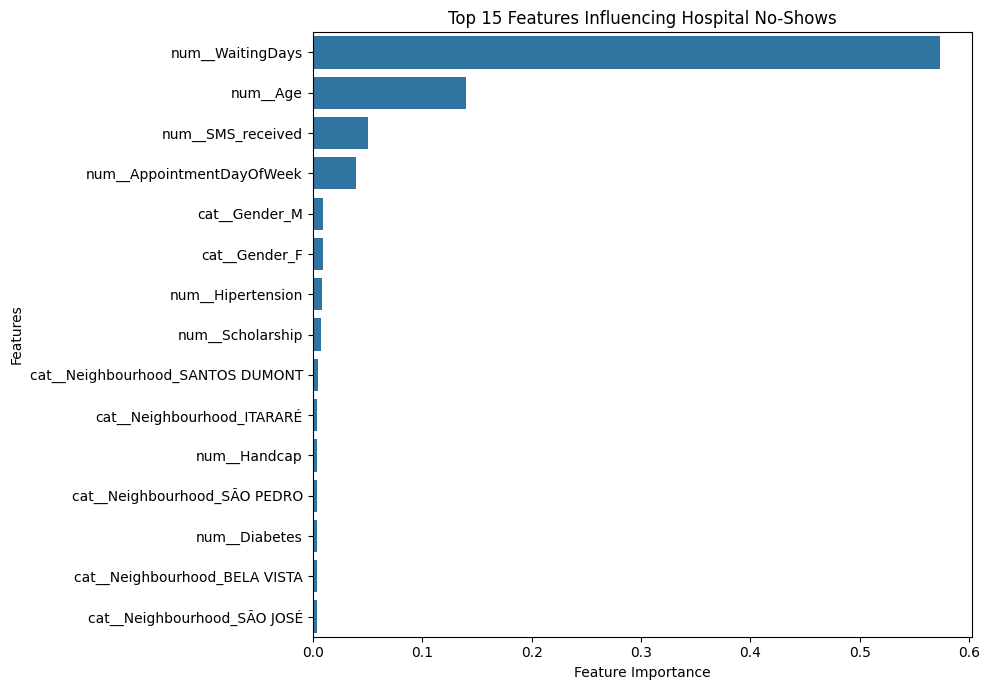

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Hospital No-Shows")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## Feature Importance Analysis

Random Forest feature importance analysis identified WaitingDays as the most influential feature, followed by Age, SMS_received, and AppointmentDayOfWeek.

### Key Findings
- WaitingDays contributes the highest feature importance.
- Age is the second most influential feature.
- SMS_received and appointment weekday also contribute to predictions.
- Neighbourhood and medical condition features have smaller individual importance scores.

These results represent model-based feature importance and do not establish causal relationships.

In [25]:
gb_param_dist = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'min_samples_leaf': [5, 10, 20],
    'subsample': [0.8, 1.0]
}

print("Gradient Boosting search space created!")

Gradient Boosting search space created!


In [27]:
gb_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=gb_param_dist,
    n_iter=5,
    scoring='f1',
    cv=2,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

gb_search.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

print("Best parameters:")
print(gb_search.best_params_)

print("\nBest CV F1-score:")
print(gb_search.best_score_)

Fitting 2 folds for each of 5 candidates, totalling 10 fits
Best parameters:
{'subsample': 1.0, 'n_estimators': 100, 'min_samples_leaf': 5, 'max_depth': 2, 'learning_rate': 0.05}

Best CV F1-score:
0.71868369752379


In [28]:
best_gb_model = gb_search.best_estimator_

tuned_gb_pred = best_gb_model.predict(X_test)

print("Tuned Gradient Boosting Accuracy:",
      accuracy_score(y_test, tuned_gb_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, tuned_gb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_gb_pred))

Tuned Gradient Boosting Accuracy: 57.43044560054287 %

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.51      0.66     17642
           1       0.30      0.84      0.44      4463

    accuracy                           0.57     22105
   macro avg       0.61      0.67      0.55     22105
weighted avg       0.80      0.57      0.61     22105


Confusion Matrix:
[[8961 8681]
 [ 729 3734]]


In [29]:
joblib.dump(best_gb_model, "../models/best_gradient_boosting.pkl")

print("Tuned Gradient Boosting model saved successfully!")

Tuned Gradient Boosting model saved successfully!


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Tuned Random Forest": best_rf_model,
    "Tuned Gradient Boosting": best_gb_model
}

final_results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

final_comparison = pd.DataFrame(final_results)

display(final_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Random Forest,0.6229,0.3196,0.7688,0.4515
1,Tuned Gradient Boosting,0.5743,0.3008,0.8367,0.4425


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

validation_model = clone(best_gb_model)
validation_model.fit(X_subtrain, y_subtrain)

val_probabilities = validation_model.predict_proba(X_val)[:, 1]

print("Validation probabilities generated!")
print("Validation samples:", len(val_probabilities))

Validation probabilities generated!
Validation samples: 17684


In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:
    predictions = (val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1 Score": f1_score(y_val, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

c:\Hospital_No_Show_Prediction\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Threshold,Precision,Recall,F1 Score
0,0.20,0.2981,0.8557,0.4421
1,0.25,0.3239,0.6812,0.4390
2,0.30,0.3553,0.4655,0.4030
3,0.35,0.4052,0.2443,0.3048
4,0.40,0.4799,0.0535,0.0963
5,0.45,0.5000,0.0006,0.0011
6,0.50,0.0000,0.0000,0.0000


In [33]:
test_probabilities = best_gb_model.predict_proba(X_test)[:, 1]

final_threshold = 0.20

final_predictions = (
    test_probabilities >= final_threshold
).astype(int)

print("Final Test Accuracy:",
      accuracy_score(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

Final Test Accuracy: 0.4614340646912463

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.34      0.50     17642
           1       0.27      0.95      0.42      4463

    accuracy                           0.46     22105
   macro avg       0.62      0.64      0.46     22105
weighted avg       0.82      0.46      0.48     22105


Confusion Matrix:
[[ 5957 11685]
 [  220  4243]]


## Final Model Evaluation

The Tuned Gradient Boosting model was evaluated using a decision threshold of 0.20.

### Key Results
- Accuracy: 46.14%
- No-show Precision: 26.64%
- No-show Recall: 95.07%
- No-show F1-score: 42%

### Conclusion
The model identifies approximately 95% of actual missed appointments.
However, it generates a significant number of false-positive predictions.

The threshold prioritizes identifying potential no-shows over overall accuracy.